# Lohoff Figure 2e recreation

Run TissueAgent from the supplied data and reference, with explicit final figures, validation, and a reproduction report. Complete run artifacts and execution state are retained under `cached/figure_recreation_lohoff-2e/`; this folder is ignored by Git. No prior run is deleted.

The supplied AnnData lacks the original segmentation/contact network. The report must distinguish the documented centroid-neighbor approximation from exact reproduction of the authors' analysis.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import shutil
import socket
import subprocess
import sys
from datetime import datetime, timezone

from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "pyproject.toml").exists():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "pyproject.toml").exists(), "Run from demo/ or the repository root."
TASK_NAME = "figure_recreation_lohoff-2e"
TASK_ID = "notebook_lohoff_2e_with_report"
MODEL = "gpt-5.5"
DATA_DIR = REPO_ROOT / "demo/data"
DATASETS = [DATA_DIR / "dataset_lohoff_et_al_seqfish.h5ad"]
REFERENCE = DATA_DIR / "reference_lohoff-2e.png"
ATTACHMENTS = [REFERENCE, DATA_DIR / "instructions_lohoff-2e.md"]
INPUTS = [*DATASETS, *ATTACHMENTS]
OUTPUT_DIR = REPO_ROOT / "cached" / TASK_NAME
PROMPT = "Recreate the spatial transcriptional heterogeneity violin plot from dataset_lohoff_et_al_seqfish.h5ad using instructions_lohoff-2e.md and reference_lohoff-2e.png. Calculate each gene/cell-type spatial-lag coefficient t-statistic from real expression data; do not infer t-statistics from reference pixels or tune them to reproduce the picture. Use the original celltype_mapped_refined labels and exclude Low quality cells. Inspect and document whether X or raw.X is used, its scale, and any justified transformation. The provided object contains embryo1, z=2 and z=5 only. Fit identifiable embryo/z terms; report that an embryo effect and its interaction cannot be independently estimated here. The original neighborhood graph/polygons are absent: reconstruct a symmetric undirected 10-NN spatial graph within each embryo/z stratum as an explicitly documented approximation. For each cell type, form the spatial-lag expression predictor using inverse shortest-path distances in the neighborhood network (exclude self; disconnected pairs have zero weight). Explain which cells contribute to the lag. The instructions describe a weighted mean but display an unnormalized sum: state which definition is implemented, with the exact formula and weight normalization; do not silently substitute Euclidean distance for graph-path distance. Fit the linear model and report the lag coefficient t-statistic, residual degrees of freedom, and numerical QC. Handle constant genes/rank deficiency explicitly. Retain negative t-values and all finite extremes, with an axis range that shows complete violins. Sort cell types by descending mean of their calculated valid t-statistics, not by the reference order. Do not invent missing reference categories. Match reference plot styling and labeled colors as closely as the real analysis supports. Save every input gene x retained cell-type combination to outputs/tables/gene_t_statistics.csv, with columns celltype, gene, t_statistic, status (status='ok' for finite valid fits, otherwise an explicit reason), plus coefficient/SE/df/QC. Save all valid finite rows used in the violins, with those same four columns, to outputs/tables/plotted_data.csv, and the calculated display order as a JSON list in outputs/tables/celltype_order.json. Report the distinction between this data-limited approximation and exact replication of the authors' analysis. Save the accepted final figure as outputs/final_figure.png and outputs/final_figure.pdf, executable plotting/analysis code as outputs/plotting_code.py, a cell-type color mapping as outputs/tables/colormap.yaml, machine-readable analysis metadata as outputs/tables/analysis_metadata.json, and a detailed reproduction report as outputs/reports/reproduction_report.md. The report must describe input fields, exclusions and sample sizes, actual computations and seeds, approximations and missing inputs, visual comparison and unresolved differences. Inspect the final PNG against the reference. The final PNG must be the requested figure, never a diagnostic grid or comparison montage. Use only the supplied inputs; do not retrieve prior TissueAgent/baseline reproductions. Do not fabricate cells, genes, computed statistics, or labels, alter individual coordinates to match an image, or paste reference pixels into the result. Document colors estimated from the reference."
INPUT_RECORDS = []
for path in INPUTS:
    assert path.is_file(), f"Missing input: {path}"
    with path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    role = "dataset" if path in DATASETS else "reference" if path == REFERENCE else "instructions"
    INPUT_RECORDS.append({"role": role, "path": str(path), "name": path.name, "sha256": digest})
print(json.dumps({"task": TASK_NAME, "model": MODEL, "inputs": INPUT_RECORDS,
                  "supplied_colormap": False, "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "task": "figure_recreation_lohoff-2e",
  "model": "gpt-5.5",
  "inputs": [
    {
      "role": "dataset",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/dataset_lohoff_et_al_seqfish.h5ad",
      "name": "dataset_lohoff_et_al_seqfish.h5ad",
      "sha256": "0588f810603cf3756a5a87d9730465a8968bb18f9c31d1b24e38f1d008305d70"
    },
    {
      "role": "reference",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/reference_lohoff-2e.png",
      "name": "reference_lohoff-2e.png",
      "sha256": "7f42e814e7b2546f7c64cca448cbac09f1f5071e5e4a91459563310378a8d74e"
    },
    {
      "role": "instructions",
      "path": "/Users/wenduoc/new_TissueAgent/TissueAgent/demo/data/instructions_lohoff-2e.md",
      "name": "instructions_lohoff-2e.md",
      "sha256": "d7ebef6ecc4c11c2f4fbece7e4398a0bffdc1d8e304c82f7a3939c2c30c23bc4"
    }
  ],
  "supplied_colormap": false,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/cached/figure_recreation_loh

## Run the CLI

Set `OPENAI_API_KEY` in the notebook environment. A fresh run makes model calls; a completed local run is reused only if model, prompt, and input hashes match. Choose a new `OUTPUT_DIR` when changing settings or requesting another fresh run. Logs, state, intermediate attempts, final figures, and reports are retained under `cached/` rather than deleted.


In [2]:
manifest_path = OUTPUT_DIR / "run_manifest.json"
metrics_path = OUTPUT_DIR / "metrics.json"
if OUTPUT_DIR.is_dir() and manifest_path.is_file() and metrics_path.is_file():
    manifest = json.loads(manifest_path.read_text())
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    expected_hashes = {record["name"]: record["sha256"] for record in INPUT_RECORDS}
    cached_hashes = {record["name"]: record["sha256"] for record in manifest["inputs"]}
    assert terminal_state == "completed" and manifest.get("cli_exit_code") == 0
    assert manifest.get("supplied_colormap") is False
    assert manifest.get("prompt") == PROMPT, "Prompt changed; choose a new OUTPUT_DIR."
    assert manifest.get("model") == MODEL, "Model changed; choose a new OUTPUT_DIR."
    assert cached_hashes == expected_hashes, "Inputs changed; choose a new OUTPUT_DIR."
    print(json.dumps({
        "terminal_state": terminal_state,
        "elapsed_seconds": manifest["elapsed_seconds"],
        "output_dir": str(OUTPUT_DIR),
        "reused_completed_output": True,
    }, indent=2))
else:
    if OUTPUT_DIR.exists():
        raise RuntimeError(f"{OUTPUT_DIR} already exists. Choose a new OUTPUT_DIR for a fresh run.")
    assert os.environ.get("OPENAI_API_KEY"), "Set OPENAI_API_KEY in the notebook environment for a fresh run."
    OUTPUT_DIR.mkdir(parents=True)
    STATE_ROOT = OUTPUT_DIR / "state"
    with socket.socket() as sock:
        sock.bind(("127.0.0.1", 0))
        gateway_port = sock.getsockname()[1]
    env = os.environ.copy()
    env.update({
        "TISSUEAGENT_STATE_ROOT": str(STATE_ROOT),
        "TISSUEAGENT_GATEWAY_PORT": str(gateway_port),
        "TISSUEAGENT_ORCHESTRATION_REASONING_EFFORT": "medium",
        "TISSUEAGENT_WORKER_REASONING_EFFORT": "high",
        "NUMBA_CACHE_DIR": str(OUTPUT_DIR / "cache/numba"),
        "MPLCONFIGDIR": str(OUTPUT_DIR / "cache/matplotlib"),
        "XDG_CACHE_HOME": str(OUTPUT_DIR / "cache/xdg"),
        "IPYTHONDIR": str(OUTPUT_DIR / "cache/ipython"),
        "JUPYTER_RUNTIME_DIR": str(OUTPUT_DIR / "cache/jupyter_runtime"),
        "PYTHONPATH": str(REPO_ROOT / "src") + os.pathsep + str(REPO_ROOT),
        "PATH": str(Path(sys.executable).parent) + os.pathsep + env.get("PATH", ""),
    })
    for key in ["NUMBA_CACHE_DIR", "MPLCONFIGDIR", "XDG_CACHE_HOME", "IPYTHONDIR", "JUPYTER_RUNTIME_DIR"]:
        Path(env[key]).mkdir(parents=True, exist_ok=True)
    command = [
        sys.executable, "-m", "cli", "--no-docker", "--json", "--model", MODEL,
        "--task-id", TASK_ID, "--seed", "0", "--attempt", "1",
        "--metrics-out", str(metrics_path),
    ]
    for dataset in DATASETS:
        command.extend(["--dataset", str(dataset)])
    for attachment in ATTACHMENTS:
        command.extend(["--attach", str(attachment)])
    command.append("-")

    transcript_path = OUTPUT_DIR / "transcript.log"
    (OUTPUT_DIR / "prompt.txt").write_text(PROMPT + "\n")
    started_at = datetime.now(timezone.utc)
    with transcript_path.open("w") as transcript:
        completed = subprocess.run(
            command, input=PROMPT, cwd=REPO_ROOT, env=env,
            stdout=transcript, stderr=subprocess.STDOUT, text=True, check=False,
        )
    finished_at = datetime.now(timezone.utc)
    project_dir = STATE_ROOT / "workspace/project"
    project_outputs = project_dir / "outputs"
    if project_outputs.is_dir():
        for source in project_outputs.iterdir():
            destination = OUTPUT_DIR / source.name
            if source.is_dir():
                shutil.copytree(source, destination, dirs_exist_ok=True)
            else:
                shutil.copy2(source, destination)
    if (project_dir / "metrics.json").is_file():
        shutil.copy2(project_dir / "metrics.json", OUTPUT_DIR / "project_metrics.json")
    if not metrics_path.is_file():
        raise RuntimeError(f"CLI exited {completed.returncode} without metrics. See {transcript_path}; state retained at {STATE_ROOT}.")
    metrics = json.loads(metrics_path.read_text())
    terminal_state = metrics.get("outcome", {}).get("terminal_state")
    manifest = {
        "task": TASK_NAME, "task_id": TASK_ID, "model": MODEL,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": finished_at.isoformat(),
        "elapsed_seconds": metrics.get("run", {}).get("wall_time_s", (finished_at - started_at).total_seconds()),
        "elapsed_seconds_definition": "CLI-reported workflow wall time, falling back to subprocess wall time",
        "command": command, "prompt": PROMPT, "inputs": INPUT_RECORDS,
        "supplied_colormap": False, "cli_exit_code": completed.returncode,
        "terminal_state": terminal_state, "state_root": str(STATE_ROOT),
    }
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
    if completed.returncode != 0 or terminal_state != "completed":
        raise RuntimeError(f"CLI failed (exit={completed.returncode}, terminal_state={terminal_state}). See {transcript_path}; state retained at {STATE_ROOT}.")
    print(json.dumps({"terminal_state": terminal_state, "elapsed_seconds": manifest["elapsed_seconds"], "output_dir": str(OUTPUT_DIR)}, indent=2))


{
  "terminal_state": "completed",
  "elapsed_seconds": 1712.38,
  "output_dir": "/Users/wenduoc/new_TissueAgent/TissueAgent/cached/figure_recreation_lohoff-2e"
}


## Validate computed and plotted data


In [3]:
import anndata as ad
import numpy as np
import pandas as pd

statistics = pd.read_csv(OUTPUT_DIR / "tables/gene_t_statistics.csv")
plotted = pd.read_csv(OUTPUT_DIR / "tables/plotted_data.csv")
order = json.loads((OUTPUT_DIR / "tables/celltype_order.json").read_text())
required = {"celltype", "gene", "t_statistic", "status"}
assert required <= set(statistics.columns) and required <= set(plotted.columns)
adata = ad.read_h5ad(DATASETS[0], backed="r")
try:
    labels = set(adata.obs["celltype_mapped_refined"].astype(str)) - {"Low quality"}
    genes = set(adata.var_names.astype(str))
finally:
    adata.file.close()
assert not statistics.duplicated(["celltype", "gene"]).any()
assert set(statistics["celltype"]) == labels and set(statistics["gene"]) == genes
assert len(statistics) == len(labels) * len(genes)
assert statistics["status"].notna().all()
valid = statistics.loc[statistics["status"] == "ok"].set_index(["celltype", "gene"]).sort_index()
actual = plotted.set_index(["celltype", "gene"]).sort_index()
assert actual.index.is_unique and actual.index.equals(valid.index)
assert (actual["status"] == "ok").all() and np.isfinite(actual["t_statistic"]).all()
np.testing.assert_allclose(actual["t_statistic"], valid["t_statistic"], rtol=0, atol=1e-10)
means = actual.groupby(level="celltype")["t_statistic"].mean()
assert len(order) == len(means) and set(order) == set(means.index)
assert np.all(np.diff(means.loc[order].to_numpy()) <= 1e-10)
print(f"Verified {len(statistics):,} gene/cell-type fits, {len(actual):,} plotted valid statistics, and descending mean-based order.")
display(means.loc[order].rename("Mean t-statistic").to_frame())


Verified 7,371 gene/cell-type fits, 7,371 plotted valid statistics, and descending mean-based order.


,Mean t-statistic
celltype,
Forebrain/Midbrain/Hindbrain,17.637837
Spinal cord,13.584563
Gut tube,11.365493
Lateral plate mesoderm,9.463870
Splanchnic mesoderm,8.711582
Surface ectoderm,7.702993
Neural crest,7.621854
Endothelium,7.199753
Mixed mesenchymal mesoderm,6.451622


## Final figure


cached/figure_recreation_lohoff-2e/final_figure.png


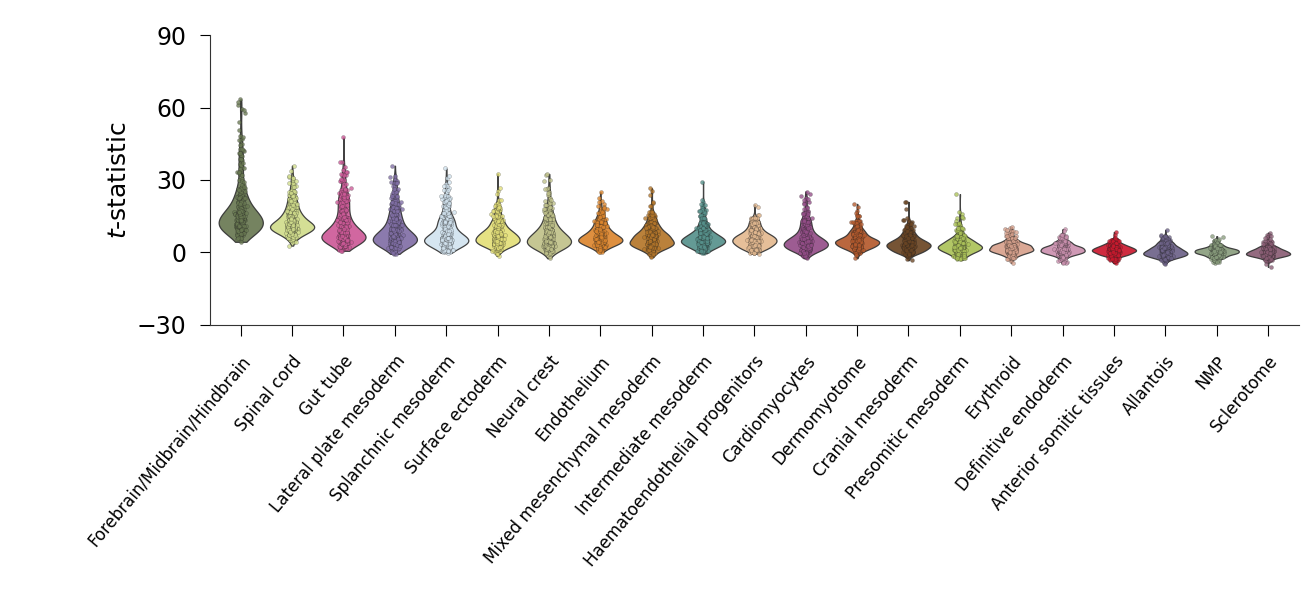

In [4]:
selected = OUTPUT_DIR / "final_figure.png"
for path in (selected, OUTPUT_DIR / "final_figure.pdf", OUTPUT_DIR / "plotting_code.py",
             OUTPUT_DIR / "tables/colormap.yaml", OUTPUT_DIR / "tables/analysis_metadata.json",
             OUTPUT_DIR / "reports/reproduction_report.md"):
    assert path.is_file(), f"Missing final artifact: {path}; inspect transcript.log."
print(selected.relative_to(REPO_ROOT))
display(Image(filename=str(selected)))


## Reproduction report


In [5]:
report_path = OUTPUT_DIR / "reports/reproduction_report.md"
print(report_path.relative_to(REPO_ROOT))
display(Markdown(report_path.read_text()))


cached/figure_recreation_lohoff-2e/reports/reproduction_report.md


# Lohoff seqFISH spatial transcriptional heterogeneity violin reproduction report

## Accepted final-figure verification

I inspected the supplied reference image `project/uploads/reference_lohoff-2e.png` directly against the accepted final PNG `project/outputs/final_figure.png`. This comparison used the final accepted PNG, not an intermediate attempt and not a diagnostic montage. The final PNG is a single violin plot as requested.

Machine-readable comparison metrics were regenerated at `project/outputs/tables/compare_metrics.json`; the side-by-side/overlay comparison written by the verification script is `project/outputs/figures/compare_figures_final.png`, and the letterboxed geometry comparison is `project/outputs/figures/compare_figures_geometry_final.png`.

Key direct final-PNG metrics:

- Reference canvas: 1312 x 590 px; accepted final canvas: 1312 x 590 px.
- pHash Hamming distance: 2.
- SSIM: 0.6251.
- ORB good matches: 123.
- Palette mean Delta-E: 12.09 over 10 matched dominant-color pairs.
- Text OCR match rate: 0.10; this is low because the plotted labels/order and y-axis range differ and OCR is noisy on rotated labels.
- Geometry/orientation check: clean; best orientation was `as_is`, with no geometry findings.

## Input files and fields

Inputs used, all supplied in the workspace:

- Dataset: `library/datasets/dataset_lohoff_et_al_seqfish.h5ad` (sha256 `0588f810603cf3756a5a87d9730465a8968bb18f9c31d1b24e38f1d008305d70`).
- Instructions: `project/uploads/instructions_lohoff-2e.md` (sha256 `d7ebef6ecc4c11c2f4fbece7e4398a0bffdc1d8e304c82f7a3939c2c30c23bc4`).
- Reference image: `project/uploads/reference_lohoff-2e.png` (sha256 `7f42e814e7b2546f7c64cca448cbac09f1f5071e5e4a91459563310378a8d74e`).

Dataset fields used:

- Cell-type labels: original `obs['celltype_mapped_refined']`.
- Spatial coordinates: `obsm['spatial']`, two numeric columns.
- Gene names: `var_names`.
- Embryo and z slice: parsed from observation names using the pattern `<embryo>_..._z<z>`.
- Expression matrix: `X` after inspecting both `X` and `raw.X`.

The supplied AnnData object contains only embryo `embryo1` and z slices `2` and `5`.

## Exclusions and sample sizes

Cells labeled `Low quality` in `celltype_mapped_refined` were excluded before graph construction, lag calculation, modeling, and plotting.

- Total cells in object: 19,416.
- Total genes in object: 351.
- Excluded Low quality cells: 1,645.
- Retained cells: 17,771.
- Retained cell types: 21.
- Gene x retained-cell-type model combinations: 7,371.
- Valid finite rows used in the violins: 7,371.
- Negative valid t-statistics retained: 915.
- Valid t-statistic range: -6.078229 to 63.420215.

Retained cell counts by cell type:

| Cell type | Cells |
|---|---:|
| Forebrain/Midbrain/Hindbrain | 3704 |
| Spinal cord | 2620 |
| Gut tube | 1464 |
| Lateral plate mesoderm | 1243 |
| Splanchnic mesoderm | 1138 |
| Endothelium | 953 |
| Neural crest | 912 |
| Surface ectoderm | 801 |
| Cardiomyocytes | 737 |
| Haematoendothelial progenitors | 637 |
| Intermediate mesoderm | 623 |
| Mixed mesenchymal mesoderm | 541 |
| Cranial mesoderm | 528 |
| Dermomyotome | 523 |
| Presomitic mesoderm | 458 |
| Erythroid | 300 |
| Definitive endoderm | 213 |
| Anterior somitic tissues | 112 |
| NMP | 109 |
| Sclerotome | 78 |
| Allantois | 77 |

Retained embryo/z strata after exclusion:

| Embryo | z | Cells |
|---|---:|---:|
| embryo1 | 2 | 10,129 |
| embryo1 | 5 | 7,642 |

## X/raw.X inspection, scale, and transformation decision

`X` and `raw.X` were inspected before modeling. They have identical shape and values in this object, including identical gene names.

- `X`: sparse `csc_matrix`, shape 19,416 x 351, 1,890,790 nonzero entries, density 0.277445.
- `raw.X`: sparse `csc_matrix`, shape 19,416 x 351, 1,890,790 nonzero entries, density 0.277445.
- Nonzero values in both matrices: minimum 1.0, maximum 98.0, mean 1.990061.
- Values are integer-valued and nonnegative.
- Per-cell row sums in both matrices: minimum 10.0, median 163.0, maximum 1,336.0.

Decision: I used `X` without transformation. Because `X == raw.X` and both contain sparse integer nonnegative counts, this is equivalent to using `raw.X` for this object. No log transformation, library-size normalization, scaling, or other expression transformation was applied.

## Neighborhood graph approximation

The original cell-cell neighborhood graph and polygon information used by the authors are absent from the supplied object. Therefore, exact author replication is impossible from the available files. As an explicitly documented approximation, I reconstructed a symmetric undirected 10-nearest-neighbor spatial graph within each embryo/z stratum after excluding Low quality cells.

Important details:

- KNN graph strata: each `(embryo, z)` stratum was handled separately.
- K: 10 nearest neighbors.
- Coordinates: `obsm['spatial']`.
- Euclidean distances were used only to choose KNN edges.
- The graph was symmetrized by adding reciprocal edges.
- Lag weights used graph shortest-path hop distances in this reconstructed network, not direct Euclidean distances.

Graph QC:

| Stratum | Cells | Undirected edges | Degree min/median/max | Connected components |
|---|---:|---:|---|---:|
| embryo1, z=2 | 10,129 | 56,934 | 10 / 11.0 / 18 | 1 |
| embryo1, z=5 | 7,642 | 43,309 | 10 / 11.0 / 20 | 1 |

## Spatial-lag formula and contributing cells

The instructions describe a weighted mean in prose but display an unnormalized sum. I implemented the prose definition: a row-normalized inverse graph-path weighted mean.

For focal cell `j`, gene `g`, and cell type `c`, let `s(j)` be the embryo/z stratum of `j`, and let `D_jk` be the unweighted shortest-path hop distance between cells `j` and `k` in the reconstructed symmetric 10-NN graph for that stratum. Define the contributor set:

`C(j,c) = { k : k != j, celltype(k) = c, s(k) = s(j), and D_jk is finite }`.

Weights and lag were computed as:

`w_jk = (1 / D_jk) / sum_{l in C(j,c)} (1 / D_jl)`

`lag_jg = sum_{k in C(j,c)} w_jk * x_kg`.

Thus the weights for contributors to a focal cell sum to 1 whenever contributors exist. Self is excluded. Cells in other embryo/z strata and disconnected cells have zero weight. In this dataset both reconstructed stratum graphs were connected, but disconnected-pair handling was still explicit in the implementation. Paths may traverse any retained cell in the same stratum graph; however, expression contributions in the weighted average come only from other retained cells of the same focal cell type and same embryo/z stratum.

If a focal cell had no contributor cells, its lag row would remain zero and downstream rank/constant-predictor checks would mark non-identifiable fits where appropriate. In the actual retained data, contributor-count minima by cell type were all positive; across cell types the per-cell contributor-count minima ranged from 31 to 1,836 depending on cell type and slice composition.

## Linear model and identifiability

For each gene x retained-cell-type combination, the fitted model was:

`expression_jg = beta0 + beta1 * lag_jg + beta2 * I[z_j == 5] + epsilon_j`.

The reported statistic is the t-statistic for `beta1`, the spatial-lag coefficient.

The original instructions include embryo and embryo:z interaction terms. These terms cannot be independently estimated here because the supplied object contains only one embryo (`embryo1`). I therefore fit only identifiable terms: intercept, spatial lag, and z-slice indicator. The report should be interpreted as a data-limited approximation, not an exact estimate of the authors' full model.

Model QC and failure handling:

- Residual degrees of freedom were computed as `n_cells - rank(design)`.
- Constant gene expression, constant lag predictor, rank deficiency, nonpositive residual degrees of freedom, nonfinite/zero standard error, nonfinite t-statistic, and linear-algebra errors were explicitly assigned non-`ok` statuses in `gene_t_statistics.csv`.
- Actual status counts: all 7,371 gene x cell-type combinations had status `ok`.
- Residual df range among valid fits: 74 to 3,701; median 620.
- Spatial-lag coefficient range among valid fits: -4.907346 to 5.388803.
- Standard-error range among valid fits: 0.035479 to 2.379070.
- Design condition number range among valid fits: 2.756875 to 175.548974; median 15.320497.
- R-squared range among valid fits: 0.000004 to 0.608392; median 0.042273.

The complete table is saved at `project/outputs/tables/gene_t_statistics.csv` with columns including `celltype`, `gene`, `t_statistic`, `status`, `coefficient`, `std_error`, `df_resid`, sample-size fields, rank/QC fields, expression source, transformation, lag definition, and model terms.

## Plotting data and display order

The plotted data are the finite valid rows from `gene_t_statistics.csv` with status `ok`; they are saved at `project/outputs/tables/plotted_data.csv` with columns `celltype`, `gene`, `t_statistic`, and `status`.

Cell types were sorted by descending mean of their calculated valid t-statistics, not by the reference order. The display order is saved as `project/outputs/tables/celltype_order.json` and is:

1. Forebrain/Midbrain/Hindbrain
2. Spinal cord
3. Gut tube
4. Lateral plate mesoderm
5. Splanchnic mesoderm
6. Surface ectoderm
7. Neural crest
8. Endothelium
9. Mixed mesenchymal mesoderm
10. Intermediate mesoderm
11. Haematoendothelial progenitors
12. Cardiomyocytes
13. Dermomyotome
14. Cranial mesoderm
15. Presomitic mesoderm
16. Erythroid
17. Definitive endoderm
18. Anterior somitic tissues
19. Allantois
20. NMP
21. Sclerotome

The y-axis range in the final figure is -30 to 90. This range intentionally retains negative t-values and shows all finite extremes in the recomputed data.

## Seeds and deterministic computations

The executable analysis/plotting code is `project/outputs/plotting_code.py`. It used random seed `1729` for the overlaid point jitter in the violin plot. The data analysis steps themselves were deterministic for the supplied inputs: X/raw.X inspection, Low quality exclusion, KNN graph construction, shortest-path distance calculation, lag construction, least-squares fitting, and display-order calculation.

## Colors estimated from the reference

The reference raster did not contain a reliable extractable legend. Colors were estimated from violin-body/dominant pixels in `reference_lohoff-2e.png`, reconciled to the retained dataset labels, and written through `build_colormap.py`. The final mapping is saved at `project/outputs/tables/colormap.yaml`. No library default palette was silently substituted.

The final color mapping is:

| Cell type | Color |
|---|---|
| Allantois | `#6e6389` |
| Anterior somitic tissues | `#cb192e` |
| Cardiomyocytes | `#954e89` |
| Cranial mesoderm | `#6a4524` |
| Definitive endoderm | `#cb91af` |
| Dermomyotome | `#b45a2d` |
| Endothelium | `#dc862e` |
| Erythroid | `#d7a18c` |
| Forebrain/Midbrain/Hindbrain | `#697952` |
| Gut tube | `#cd5a98` |
| Haematoendothelial progenitors | `#e4ba91` |
| Intermediate mesoderm | `#57928c` |
| Lateral plate mesoderm | `#816fa6` |
| Mixed mesenchymal mesoderm | `#b4762a` |
| Neural crest | `#c0c28a` |
| NMP | `#8a9e7e` |
| Presomitic mesoderm | `#acc359` |
| Sclerotome | `#8b5e75` |
| Spinal cord | `#d1dd8c` |
| Splanchnic mesoderm | `#d2e3ef` |
| Surface ectoderm | `#e3df78` |

The reference includes or appears to include category labels that are absent or differently named in the retained dataset, including a rightmost `Blood progenitors` category and a shortened mesenchyme-type label. These categories were not invented in the output. Only retained labels from the supplied dataset were plotted.

## Visual comparison against the reference

The accepted final PNG and reference both show a single horizontal row of colored cell-type violins on a white background, with rotated x-axis labels and a y-axis labeled `t-statistic`. The final figure has the same 1312 x 590 pixel canvas and the same broad landscape aspect as the reference. The verification script found no geometry/canvas/orientation/layout defects.

Visible remaining differences after direct accepted-PNG inspection:

- The reference y-axis extends to approximately 120, whereas the accepted final figure extends from -30 to 90. The final range is driven by recomputed finite t-statistics and intentionally includes negative values.
- The reference order is not used because the user requested sorting by descending mean of the calculated valid t-statistics. Therefore, label order and color positions differ from the reference.
- Some reference categories are missing or differently named in the supplied retained dataset; no missing category was fabricated.
- Violin heights, widths, tails, and point densities differ because t-statistics were recomputed from real expression values using the available embryo1 z=2/z=5 object and a reconstructed graph, not inferred from the reference image.
- Palette matching is approximate because colors were estimated from raster pixels without a reliable legend; palette mean Delta-E was 12.09.
- The OCR text metric is poor, mostly reflecting rotated labels, different category order/set, and noisy OCR; it should not be interpreted as fabrication or as use of a different figure type.

## Distinction from exact author replication

This output is a data-limited approximation, not an exact reproduction of the authors' original analysis. The key limitations are:

1. The supplied object contains only embryo1 and z=2/z=5, so an embryo effect and embryo:z interaction cannot be independently estimated.
2. The original neighborhood graph/polygons are absent, so a symmetric undirected 10-NN spatial graph within embryo/z strata was reconstructed as an approximation.
3. The instructions' formula displays an unnormalized sum despite describing a weighted mean; this analysis implemented the normalized weighted mean and documents the exact formula.
4. Only supplied retained dataset labels were plotted; missing reference-only categories were not invented.
5. All t-statistics were computed from real expression data in the supplied object; no t-statistics were inferred from reference pixels, tuned to match the picture, or fabricated.

## Output artifacts

- Accepted final PNG: `project/outputs/final_figure.png`.
- Accepted final PDF: `project/outputs/final_figure.pdf`.
- Executable analysis/plotting code: `project/outputs/plotting_code.py`.
- All gene x retained-cell-type statistics: `project/outputs/tables/gene_t_statistics.csv`.
- Plotted finite valid rows: `project/outputs/tables/plotted_data.csv`.
- Display order: `project/outputs/tables/celltype_order.json`.
- Color mapping: `project/outputs/tables/colormap.yaml`.
- Machine-readable analysis metadata: `project/outputs/tables/analysis_metadata.json`.
- Direct final-PNG comparison metrics: `project/outputs/tables/compare_metrics.json`.
- This reproduction report: `project/outputs/reports/reproduction_report.md`.
